# 32b. Diagnóstico de entrenamiento y evaluación complementaria de NAGFuse-B

Este cuaderno repite para NAGFuse-B los análisis que los cuadernos {doc}`26a_e3_curvas_entrenamiento`,
{doc}`27a_e3_pruebas_hipotesis` y {doc}`28a_e3_evaluacion_ampliada` hacen para la versión A: curvas de entrenamiento y
sobreajuste, verificación de la corrección de Holm, sensibilidad del veredicto, comparación global, F1 por clase,
predicción conforme, calibración, sensibilidad de la compuerta, análisis por rama y análisis de errores. Todo se calcula
desde las 20 corridas versionadas de NAGFuse-B (`entregable3/results/results_e2/NAGFuse-B/`) y desde las tablas de
`entregable3/resultados/` y `entregable3/resultados_b/`. Ningún análisis de este cuaderno es confirmatorio: la decisión
sobre R3 es la del capítulo 32.

In [1]:
# Configuración común. El cuaderno funciona desde docs/ (Jupyter Book) o desde la raíz del repositorio.
from pathlib import Path
import json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable3").is_dir())
RES, RESB = REPO / "entregable3" / "resultados", REPO / "entregable3" / "resultados_b"
RUNS = REPO / "entregable3" / "results" / "results_e2"
FIG = REPO / "docs" / "images" / "e3"
CLASES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
COLOR = {"NAGFuse-B": "#e67e22", "NAGFuse": "#c0392b", "ViT-B16": "#2e86c1", "RWCNet": "#27ae60", "GFN": "#8e44ad", "Celik-HC": "#d68910"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.precision", 4)

class LectorSinTorch(pickle.Unpickler):
    """Lee los .pkl de las corridas sin instalar torch: las clases ausentes se sustituyen por objetos vacíos."""
    def find_class(self, modulo, nombre):
        try:
            return super().find_class(modulo, nombre)
        except (ImportError, AttributeError):
            return type(nombre, (), {"__init__": lambda s, *a, **k: None, "__setstate__": lambda s, x: None})

def leer(p):
    with open(p, "rb") as f:
        return LectorSinTorch(f).load()

def semillas(modelo):
    """Carpetas de las corridas terminadas (con archivo DONE) de un modelo, ordenadas por semilla."""
    return {int(s.name[5:]): s for s in sorted((RUNS / modelo).glob("seed_*")) if (s / "DONE").exists()}

def f1_macro(y, yp, k=6):
    return np.mean([2 * np.sum((yp == c) & (y == c)) / max(np.sum(yp == c) + np.sum(y == c), 1) for c in range(k)])

print("Repositorio:", REPO.name, "| semillas de NAGFuse-B:", list(semillas("NAGFuse-B")))

Repositorio: deep-learning-colaborativo | semillas de NAGFuse-B: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


## 1. Curvas de entrenamiento y sobreajuste (equivalente a 26a)

In [2]:
# Historiales por época de NAGFuse-B, NAGFuse (A) y los dos rivales más fuertes
def historiales(modelo):
    filas = []
    for s, d in semillas(modelo).items():
        h, t = leer(d / "history.pkl"), leer(d / "timing.pkl")       # dict de listas (una entrada por época) y tiempos
        filas.append(pd.DataFrame({"modelo": modelo, "semilla": s, "epoca": h["epoch"],
                                   "train_loss": h["train_loss"], "val_loss": h["val_loss"],
                                   "train_f1": h["train_f1_macro"], "val_f1": h["val_f1_macro"],
                                   "mejor_epoca": t["best_epoch"]}))
    return pd.concat(filas)

MODELOS = ["NAGFuse-B", "NAGFuse", "ViT-B16", "RWCNet"]
H = pd.concat([historiales(m) for m in MODELOS], ignore_index=True)
H.groupby("modelo").semilla.nunique()

modelo
NAGFuse      20
NAGFuse-B    20
RWCNet       12
ViT-B16      12
Name: semilla, dtype: int64

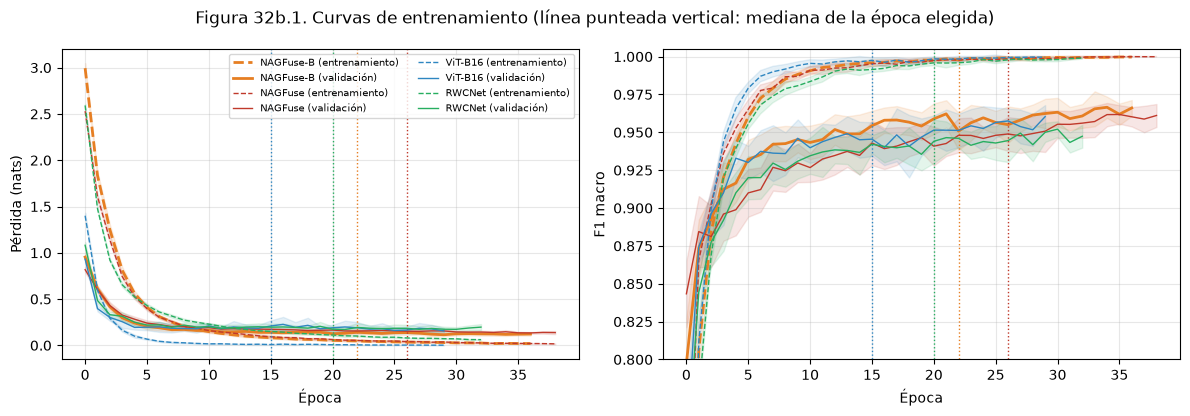

In [3]:
# Figura 32b.1 (images/e3/opcion_b_curvas.png): pérdida y F1 macro por época, media ± DE entre semillas
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, met, nombre in [(ejes[0], "loss", "Pérdida (nats)"), (ejes[1], "f1", "F1 macro")]:
    for m in MODELOS:
        g = H[H.modelo == m].groupby("epoca")
        for parte, estilo in [("train", "--"), ("val", "-")]:
            col = f"{parte}_{met}"
            n = g[col].count(); ok = n >= max(2, n.max() / 2)      # épocas a las que llegó al menos la mitad de las semillas
            mu, sd = g[col].mean()[ok], g[col].std().fillna(0)[ok]
            ax.plot(mu.index, mu, estilo, color=COLOR[m], lw=2 if m == "NAGFuse-B" else 1,
                    label=f"{m} ({'entrenamiento' if parte == 'train' else 'validación'})")
            ax.fill_between(mu.index, mu - sd, mu + sd, color=COLOR[m], alpha=0.12)
        ax.axvline(H[H.modelo == m].groupby("semilla").mejor_epoca.first().median(), color=COLOR[m], ls=":", lw=1)
    ax.set_xlabel("Época"); ax.set_ylabel(nombre)
ejes[1].set_ylim(0.8, 1.005); ejes[0].legend(fontsize=7, ncol=2)
fig.suptitle("Figura 32b.1. Curvas de entrenamiento (línea punteada vertical: mediana de la época elegida)")
plt.tight_layout()
fig.savefig(FIG / "opcion_b_curvas.png", dpi=150, bbox_inches="tight")

In [4]:
# Tabla 32b.1: diagnóstico de sobreajuste en la época elegida (media y DE entre semillas)
def en_mejor(d):
    r = d[d.epoca == d.mejor_epoca.iloc[0]].iloc[0]
    return pd.Series({"mejor_epoca": r.epoca, "epocas_corridas": d.epoca.max() + 1, "F1_train": r.train_f1,
                      "F1_val": r.val_f1, "brecha_F1": r.train_f1 - r.val_f1, "perdida_train": r.train_loss,
                      "perdida_val": r.val_loss})

D = H.groupby(["modelo", "semilla"]).apply(en_mejor, include_groups=False)
SOBRE = D.groupby("modelo").agg(["mean", "std"]).round(4).loc[MODELOS]
SOBRE.columns = [f"{a} ({'media' if b == 'mean' else 'DE'})" for a, b in SOBRE.columns]
SOBRE

,mejor_epoca (media),mejor_epoca (DE),epocas_corridas (media),epocas_corridas (DE),F1_train (media),F1_train (DE),F1_val (media),F1_val (DE),brecha_F1 (media),brecha_F1 (DE),perdida_train (media),perdida_train (DE),perdida_val (media),perdida_val (DE)
modelo,,,,,,,,,,,,,,
NAGFuse-B,25.4000,12.9143,37.7000,11.2535,0.9976,0.0035,0.9730,0.0058,0.0246,0.0060,0.0548,0.0464,0.1204,0.0193
NAGFuse,26.9000,10.8865,39.7000,10.4484,0.9979,0.0024,0.9665,0.0063,0.0314,0.0054,0.0506,0.0341,0.1335,0.0145
ViT-B16,15.4167,6.5430,28.4167,6.5430,0.9949,0.0075,0.9648,0.0065,0.0301,0.0054,0.0170,0.0247,0.1517,0.0351
RWCNet,19.1667,9.3501,32.1667,9.3501,0.9924,0.0083,0.9587,0.0077,0.0337,0.0070,0.1456,0.0884,0.1626,0.0292


**Interpretación.** NAGFuse-B sigue el mismo patrón de *fine-tuning* que A y los rivales: la pérdida de
entrenamiento baja casi a cero y la de validación se estabiliza después de las primeras épocas, mientras el F1 de
validación se mantiene estable. En los dos modelos de fusión la pérdida de entrenamiento incluye la supervisión de cada
rama (NLL de la mezcla más 0.5 por la entropía cruzada de cada rama), por eso empieza más alta; la de validación es la
entropía cruzada de la mezcla. En la época elegida, NAGFuse-B tiene el mayor F1 de validación y la menor brecha con el de
entrenamiento de los cuatro modelos. ViT-B16 y RWCNet muestran 12 semillas (8 a 19), las que se entrenaron en el
Entregable 3, como en el cuaderno 26a. La brecha entre el F1 de entrenamiento y el de validación en la época elegida mide el
sobreajuste que queda después del *early stopping*. La curva de aprendizaje frente al tamaño de muestra (10 %, 25 % y
50 % del entrenamiento) no se calculó para ningún modelo, por presupuesto de cómputo (capítulos 26a y 30).

## 2. Pruebas de hipótesis (equivalente a 27a)

In [5]:
# Verificación independiente de la corrección de Holm para H1-B y H2-B (decisión: máximo de las tres pruebas)
def holm(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p)
    aj = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o]))
    out = np.empty(m); out[o] = aj
    return out

ALFA_B, DELTA = 0.025, 0.02
H1 = pd.read_csv(RESB / "contrastes_H1_f1.csv"); H2 = pd.read_csv(RESB / "contrastes_H2_ruido005.csv")
for nombre, t in [("H1-B", H1), ("H2-B", H2)]:
    p_max = np.max([holm(t[c]) for c in ["p_t", "p_w", "p_boot"]], axis=0)
    supera = (p_max < ALFA_B) & (t.media_dif > DELTA) & (t.ic_lo > 0)
    print(f"{nombre}: m = {len(t)}, discrepancia máxima de Holm = {np.abs(p_max - t.p_max_holm).max():.1e}, "
          f"mismo veredicto: {bool((supera == t.supera).all())}, supera a {int(supera.sum())}")
    assert np.allclose(p_max, t.p_max_holm) and (supera == t.supera).all()

H1-B: m = 12, discrepancia máxima de Holm = 0.0e+00, mismo veredicto: True, supera a 10
H2-B: m = 10, discrepancia máxima de Holm = 0.0e+00, mismo veredicto: True, supera a 9


In [6]:
# Tabla 32b.2: sensibilidad del veredicto de H1-B a la métrica (MCC) y al subconjunto de semillas (0–9)
MCC = pd.read_csv(RESB / "contrastes_H1_mcc.csv").set_index("rival")
S09 = pd.read_csv(RESB / "contrastes_H1_seeds0-9.csv").set_index("rival")
sens = pd.DataFrame({"F1, 20 semillas": H1.set_index("rival").supera, "MCC, 20 semillas": MCC.supera,
                     "F1, semillas 0–9": S09.supera, "dif. F1 semillas 0–9": S09.media_dif.round(4)})
sens["veredicto estable"] = sens.iloc[:, :3].nunique(axis=1) == 1
sens

,"F1, 20 semillas","MCC, 20 semillas","F1, semillas 0–9",dif. F1 semillas 0–9,veredicto estable
rival,,,,,
Celik-HC,True,True,True,0.0330,True
MbXception,True,True,True,0.0844,True
ViT-B16,False,False,False,0.0106,True
GFN,True,True,True,0.0245,True
FocusRCNet,True,True,True,0.1382,True
ResMsCapsule,True,True,True,0.0455,True
RWCNet,False,False,False,0.0051,True
CNN,True,True,True,0.1259,True
MobileNetV2,True,True,True,0.1388,True


χ²_F = 109.36, F_ID = 113.10, p = 4.2e-53, CD = 4.36


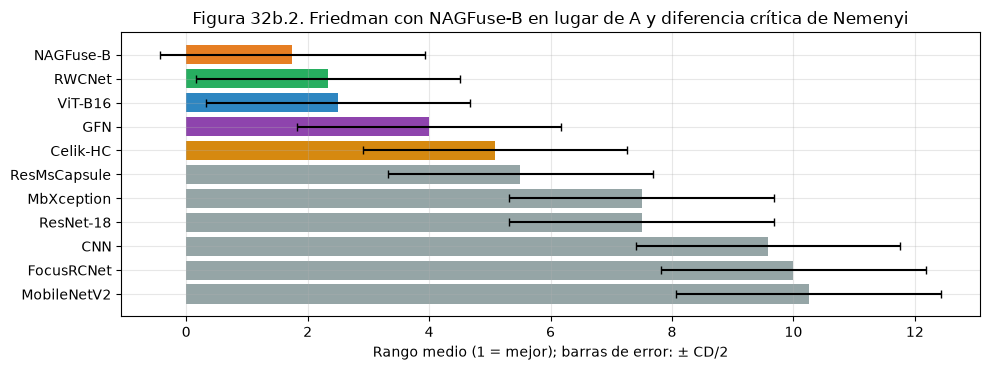

In [7]:
# Figura 32b.2: rango medio de Friedman con la diferencia crítica de Nemenyi (11 modelos, semillas 0 a 11)
F = pd.read_csv(RESB / "friedman_nemenyi.csv").sort_values("rango_medio")
print(f"χ²_F = {F.chi2.iloc[0]:.2f}, F_ID = {F.F_ID.iloc[0]:.2f}, p = {F.p.iloc[0]:.1e}, CD = {F.CD.iloc[0]:.2f}")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(F.modelo, F.rango_medio, xerr=F.CD.iloc[0] / 2, color=[COLOR.get(m, "#95a5a6") for m in F.modelo],
        error_kw=dict(ecolor="black", capsize=3))
ax.invert_yaxis(); ax.set_xlabel("Rango medio (1 = mejor); barras de error: ± CD/2")
ax.set_title("Figura 32b.2. Friedman con NAGFuse-B en lugar de A y diferencia crítica de Nemenyi")
plt.tight_layout()

## 3. Evaluación ampliada (equivalente a 28a)

In [8]:
# Tabla 32b.3: F1 por clase en prueba (media entre semillas) de NAGFuse-B, A y los dos rivales más fuertes
filas = []
for m in MODELOS:
    for s, d in semillas(m).items():
        filas.append({"modelo": m, "semilla": s, **leer(d / "metrics_test.pkl")["f1_per_class"]})
PC = pd.DataFrame(filas).groupby("modelo")[CLASES].mean().loc[MODELOS]
PC["peor clase"] = PC[CLASES].idxmin(axis=1)
PC.round(4)

,cardboard,glass,metal,paper,plastic,trash,peor clase
modelo,,,,,,,
NAGFuse-B,0.9873,0.9548,0.9595,0.9605,0.9426,0.8816,trash
NAGFuse,0.9800,0.9366,0.9529,0.9463,0.9285,0.8744,trash
ViT-B16,0.9878,0.9329,0.9505,0.9597,0.9219,0.8589,trash
RWCNet,0.9700,0.9373,0.9514,0.9503,0.9358,0.8440,trash


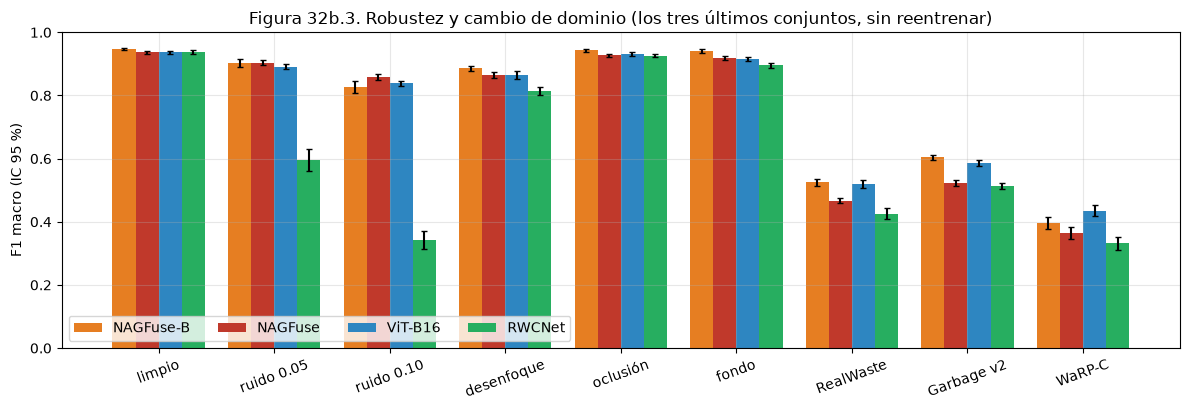

In [9]:
# Figura 32b.3: F1 macro por escenario (barras con IC 95 %) para NAGFuse-B, A y los dos rivales más fuertes
M = pd.read_csv(RES / "tabla_maestra.csv").set_index("modelo")
ESC = ["F1 limpio", "F1 ruido 0.05", "F1 ruido 0.10", "F1 desenfoque", "F1 oclusión", "F1 fondo",
       "F1 RealWaste", "F1 Garbage v2", "F1 WaRP-C"]
w = 0.2
fig, ax = plt.subplots(figsize=(12, 4.2))
for i, m in enumerate(MODELOS):
    y = M.loc[m, ESC].astype(float).values
    err = [y - M.loc[m, [c + " IC_lo" for c in ESC]].values, M.loc[m, [c + " IC_hi" for c in ESC]].values - y]
    ax.bar(np.arange(len(ESC)) + (i - 1.5) * w, y, w, yerr=err, capsize=2, color=COLOR[m], label=m)
ax.set_xticks(np.arange(len(ESC)), [c.replace("F1 ", "") for c in ESC], rotation=20)
ax.set_ylabel("F1 macro (IC 95 %)"); ax.set_ylim(0, 1); ax.legend(ncol=4)
ax.set_title("Figura 32b.3. Robustez y cambio de dominio (los tres últimos conjuntos, sin reentrenar)")
plt.tight_layout()

In [10]:
# Tabla 32b.4: predicción conforme dividida (LAC, alfa = 0.10) de NAGFuse-B con el mismo código que conforme.py,
# junto a la tabla congelada de A y los rivales (entregable3/resultados/conforme.csv)
A_CONF = 0.10
filas = []
for s, d in semillas("NAGFuse-B").items():
    v, t = leer(d / "val_predictions.pkl"), leer(d / "test_predictions.pkl")
    pv, yv, pt, yt = np.asarray(v["probs"]), np.asarray(v["y_true"]), np.asarray(t["probs"]), np.asarray(t["y_true"])
    sc = 1 - pv[np.arange(len(yv)), yv]; n = len(sc)                         # puntaje de no conformidad en validación
    q = np.quantile(sc, np.ceil((n + 1) * (1 - A_CONF)) / n, method="higher")
    S = (1 - pt) <= q; cob = S[np.arange(len(yt)), yt]                       # conjuntos y cobertura en prueba
    filas.append({"modelo": "NAGFuse-B", "semilla": s, "cobertura": cob.mean(), "tamano": S.sum(1).mean(),
                  "vacios": (S.sum(1) == 0).mean(), **{f"cob_{c}": cob[yt == k].mean() for k, c in enumerate(CLASES)}})
CB = pd.DataFrame(filas)
fila_b = CB.drop(columns="semilla").groupby("modelo").mean()
fila_b["R"] = len(CB); fila_b["peor_clase"] = fila_b[[f"cob_{c}" for c in CLASES]].min(axis=1)
CONF = pd.concat([fila_b.drop(columns="vacios"), pd.read_csv(RES / "conforme.csv").set_index("modelo")])
print(f"NAGFuse-B: fracción media de conjuntos vacíos = {fila_b.vacios.iloc[0]:.3f}")
CONF[["R", "cobertura", "tamano"] + [f"cob_{c}" for c in CLASES]].sort_values("cobertura", ascending=False).round(3)

NAGFuse-B: fracción media de conjuntos vacíos = 0.103


,R,cobertura,tamano,cob_cardboard,cob_glass,cob_metal,cob_paper,cob_plastic,cob_trash
modelo,,,,,,,,,
RWCNet,20,0.884,0.900,0.899,0.888,0.919,0.933,0.812,0.755
GFN,20,0.883,0.911,0.912,0.865,0.923,0.933,0.820,0.737
NAGFuse-B,20,0.882,0.897,0.924,0.901,0.921,0.929,0.781,0.718
Celik-HC,20,0.882,0.915,0.923,0.901,0.896,0.937,0.807,0.663
NAGFuse,20,0.879,0.896,0.917,0.890,0.917,0.922,0.782,0.763
ViT-B16,20,0.872,0.890,0.934,0.874,0.878,0.916,0.803,0.700


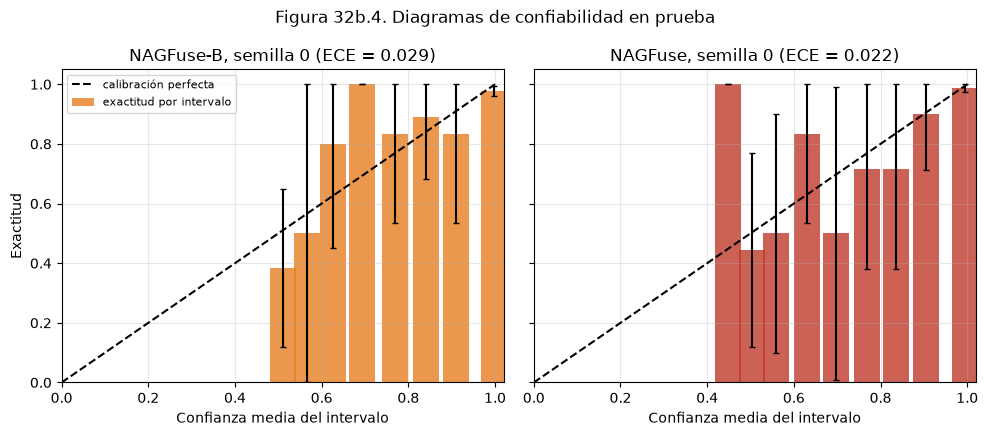

In [11]:
# Figura 32b.4 (images/e3/opcion_b_confiabilidad.png): diagramas de confiabilidad de NAGFuse-B y de A (semilla 0)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for ax, m in zip(ejes, ["NAGFuse-B", "NAGFuse"]):
    tp = leer(semillas(m)[0] / "test_predictions.pkl")
    P, y = np.asarray(tp["probs"]), np.asarray(tp["y_true"])
    conf, acierto = P.max(1), (P.argmax(1) == y).astype(float)
    b = np.minimum((conf * 15).astype(int), 14)                              # 15 intervalos de confianza de igual ancho
    n = np.bincount(b, minlength=15)
    acc = np.bincount(b, acierto, 15) / np.maximum(n, 1); cmed = np.bincount(b, conf, 15) / np.maximum(n, 1)
    ece = np.sum(n / len(y) * np.abs(acc - cmed)); v = n > 0
    ee = np.sqrt(acc[v] * (1 - acc[v]) / n[v]) * 1.96                        # IC 95 % binomial aproximado
    err = [np.minimum(ee, acc[v]), np.minimum(ee, 1 - acc[v])]               # el intervalo se recorta a [0, 1]
    ax.bar(cmed[v], acc[v], width=0.06, yerr=err, capsize=2, color=COLOR[m], alpha=0.8, label="exactitud por intervalo")
    ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
    ax.plot([0, 1], [0, 1], "k--", label="calibración perfecta")
    ax.set_xlabel("Confianza media del intervalo"); ax.set_title(f"{m}, semilla 0 (ECE = {ece:.3f})")
ejes[0].set_ylabel("Exactitud"); ejes[0].legend(fontsize=8)
fig.suptitle("Figura 32b.4. Diagramas de confiabilidad en prueba")
plt.tight_layout()
fig.savefig(FIG / "opcion_b_confiabilidad.png", dpi=150, bbox_inches="tight")

In [12]:
# Tabla 32b.5: calibración antes y después del escalado de temperatura (ajustado en validación), media entre semillas
filas = []
for m in ["NAGFuse-B", "NAGFuse", "ViT-B16", "RWCNet", "GFN"]:
    for s, d in semillas(m).items():
        if (d / "calibration.pkl").exists():
            c = leer(d / "calibration.pkl")
            if c.get("aplicable"):
                filas.append({"modelo": m, "T": c["temperature"], **{f"{k} antes": c["antes"][k] for k in ["ece", "nll", "brier"]},
                              **{f"{k} después": c["despues"][k] for k in ["ece", "nll", "brier"]}})
CAL = pd.DataFrame(filas).groupby("modelo").mean().loc[["NAGFuse-B", "NAGFuse", "ViT-B16", "RWCNet", "GFN"]]
CAL.round(4)

,T,ece antes,nll antes,brier antes,ece después,nll después,brier después
modelo,,,,,,,
NAGFuse-B,1.1167,0.0268,0.1718,0.0120,0.0252,0.1642,0.0120
NAGFuse,1.0752,0.0297,0.1911,0.0142,0.0282,0.1879,0.0141
ViT-B16,1.2346,0.0365,0.2143,0.0149,0.0291,0.1917,0.0145
RWCNet,1.2749,0.0312,0.1944,0.0146,0.0238,0.1785,0.0142
GFN,1.5564,0.0509,0.3055,0.0179,0.0319,0.2294,0.0167


## 4. Mecanismo: ramas, compuerta y errores (equivalente a la parte de mecanismo de 28a)

In [13]:
# Salidas por imagen guardadas en cada corrida (nagfuse_analisis.pkl): sigma estimada, pi, p de cada rama, por condición
def analisis(modelo):
    out = {}
    for s, d in semillas(modelo).items():
        a = leer(d / "nagfuse_analisis.pkl"); y = np.asarray(leer(d / "test_predictions.pkl")["y_true"])
        out[s] = (a, y)
    return out

AN = {m: analisis(m) for m in ["NAGFuse-B", "NAGFuse"]}
CONDS = ["limpio", "ruido_0.05", "ruido_0.10"]
filas = []
for m, runs in AN.items():
    for s, (a, y) in runs.items():
        for c in CONDS:
            v = a["detalles"][c]; pi = v["pi"][:, None]
            filas.append({"modelo": m, "semilla": s, "cond": c,
                          "F1 mezcla": f1_macro(y, (pi * v["p_v"] + (1 - pi) * v["p_c"]).argmax(1)),
                          "F1 compuerta apagada": f1_macro(y, (a["pi0"] * v["p_v"] + (1 - a["pi0"]) * v["p_c"]).argmax(1)),
                          "F1 rama robusta": f1_macro(y, v["p_v"].argmax(1)), "F1 rama CNN": f1_macro(y, v["p_c"].argmax(1)),
                          "sigma mediana": np.median(v["sigma"]), "fracción pi = 1": np.mean(v["pi"] >= 1 - 1e-6)})
RAMAS = pd.DataFrame(filas)
# Control. La mezcla recombinada aquí reproduce el F1 oficial de cada condición. La compuerta apagada de analisis_b.py
# (mecanismo.csv) sale de una pasada propia del modelo en el worker; aquí se recombina con las salidas por rama, que se
# guardan en float16, de modo que unas pocas predicciones cercanas al empate cambian y el F1 difiere en algunas semillas.
MEC = pd.read_csv(RESB / "mecanismo.csv").set_index("semilla")
rb = RAMAS[(RAMAS.modelo == "NAGFuse-B") & (RAMAS.cond == "ruido_0.05")].set_index("semilla")
print(f"Mezcla recombinada frente al F1 oficial con ruido 0.05: {rb['F1 mezcla'].mean():.4f} frente a "
      f"{MEC.f1_ruido005_on.mean():.4f}")
print(f"Compuerta apagada: media {rb['F1 compuerta apagada'].mean():.4f} aquí y {MEC.f1_ruido005_off.mean():.4f} en "
      f"mecanismo.csv; diferencia máxima por semilla {float(np.abs(rb['F1 compuerta apagada'] - MEC.f1_ruido005_off).max()):.4f}")
# Tabla 32b.6: F1 de la mezcla y de cada rama dentro del mismo modelo (sin reentrenar), media entre semillas
RAMAS.groupby(["modelo", "cond"])[["F1 mezcla", "F1 compuerta apagada", "F1 rama robusta", "F1 rama CNN",
                                   "sigma mediana", "fracción pi = 1"]].mean().round(4)

Mezcla recombinada frente al F1 oficial con ruido 0.05: 0.9034 frente a 0.9034
Compuerta apagada: media 0.8975 aquí y 0.8971 en mecanismo.csv; diferencia máxima por semilla 0.0081


F1 mezcla  F1 compuerta apagada  F1 rama robusta  \
modelo    cond                                                           
NAGFuse   limpio         0.9365                0.9365           0.9252   
          ruido_0.05     0.9035                0.9009           0.9035   
          ruido_0.10     0.8594                0.8449           0.8594   
NAGFuse-B limpio         0.9477                0.9477           0.9433   
          ruido_0.05     0.9034                0.8975           0.9034   
          ruido_0.10     0.8270                0.8162           0.8270   

                      F1 rama CNN  sigma mediana  fracción pi = 1  
modelo    cond                                                     
NAGFuse   limpio           0.9242         0.0000              0.0  
          ruido_0.05       0.6373         0.0507              1.0  
          ruido_0.10       0.3824         0.0982              1.0  
NAGFuse-B limpio           0.9211         0.0000              0.0  
          ruido_0.05       0.6479         0.0507              1.0  
          ruido_0.10       0.3810         0.0982              1.0

In [14]:
# Tabla 32b.7: las predicciones P1 a P5 del protocolo evaluadas en NAGFuse-B (exploratorio; en A eran secundarias)
r = RAMAS[RAMAS.modelo == "NAGFuse-B"].pivot_table(index="semilla", columns="cond", values=["F1 mezcla", "F1 compuerta apagada"])
d005 = (r["F1 mezcla"]["ruido_0.05"] - r["F1 compuerta apagada"]["ruido_0.05"])
d0 = (r["F1 mezcla"]["limpio"] - r["F1 compuerta apagada"]["limpio"])
RUN = pd.read_csv(RES / "por_corrida.csv")
def serie(m, col): return RUN[RUN.model == m].set_index("seed")[col]
v005 = (serie("NAGFuse-B", "rob_ruido_0.05") - serie("RWCNet", "rob_ruido_0.05")).dropna()
v010 = (serie("NAGFuse-B", "rob_ruido_0.10") - serie("RWCNet", "rob_ruido_0.10")).dropna()
sg = RAMAS[RAMAS.modelo == "NAGFuse-B"].groupby("cond")["sigma mediana"].mean()
fpi = RAMAS[(RAMAS.modelo == "NAGFuse-B") & (RAMAS.cond == "ruido_0.05")]["fracción pi = 1"]
pd.DataFrame([
    {"predicción": "P1. Apagar la compuerta reduce el F1 con σ = 0.05 en al menos δ",
     "resultado en B": f"{d005.mean():+.4f} (t pareada p = {stats.ttest_rel(r['F1 mezcla']['ruido_0.05'], r['F1 compuerta apagada']['ruido_0.05']).pvalue:.3f})",
     "¿se cumple?": "No" if d005.mean() < DELTA else "Sí"},
    {"predicción": "P2. Apagar la compuerta no cambia el F1 limpio en más de 0.005",
     "resultado en B": f"{d0.mean():+.4f} (máximo absoluto por semilla {d0.abs().max():.4f})", "¿se cumple?": "Sí" if abs(d0.mean()) <= 0.005 else "No"},
    {"predicción": "P3. La ventaja sobre la mejor CNN (RWCNet) crece de σ = 0.05 a 0.10",
     "resultado en B": f"{v005.mean():.3f} → {v010.mean():.3f}", "¿se cumple?": "Sí" if v010.mean() > v005.mean() else "No"},
    {"predicción": "P4. σ̂ crece con σ y la compuerta se abre del todo en ≥ 95 % de las imágenes con σ = 0.05",
     "resultado en B": f"σ̂: {sg['limpio']:.3f} / {sg['ruido_0.05']:.3f} / {sg['ruido_0.10']:.3f}; π = 1 en {100 * fpi.min():.0f} % (mínimo entre semillas)",
     "¿se cumple?": "Sí" if fpi.min() >= 0.95 and sg["ruido_0.10"] > sg["ruido_0.05"] > sg["limpio"] else "No"},
    {"predicción": "P5. La contracción de Haar mejora la rama CNN con ruido",
     "resultado en B": "No evaluable: exige la variante sin contracción reentrenada, que no se entrenó para B", "¿se cumple?": "—"},
])

,predicción,resultado en B,¿se cumple?
0,P1. Apagar la compuerta reduce el F1 con σ = 0...,+0.0059 (t pareada p = 0.006),No
1,P2. Apagar la compuerta no cambia el F1 limpio...,+0.0000 (máximo absoluto por semilla 0.0000),Sí
2,P3. La ventaja sobre la mejor CNN (RWCNet) cre...,0.307 → 0.484,Sí
3,P4. σ̂ crece con σ y la compuerta se abre del ...,σ̂: 0.000 / 0.051 / 0.098; π = 1 en 100 % (mín...,Sí
4,P5. La contracción de Haar mejora la rama CNN ...,No evaluable: exige la variante sin contracció...,—


In [15]:
# Tabla 32b.8: sensibilidad del F1 a rho y s_lo en NAGFuse-B (20 semillas). pi se recalcula con las salidas guardadas
# de cada rama y la mezcla se rehace sin reentrenar, porque ninguna rama depende de rho ni de s_lo. Exploratorio.
SLO = 0.014535
filas = []
for rho in [1.5, 2.0, 3.0, 4.0]:
    for fac in [0.5, 1.0, 2.0]:
        fila = {"ρ": rho, "s_lo": f"{fac} × {SLO}"}
        for c in CONDS:
            f1s = []
            for s, (a, y) in AN["NAGFuse-B"].items():
                v = a["detalles"][c]; s_lo = fac * SLO
                g = np.clip((v["sigma"] - s_lo) / ((rho - 1) * s_lo), 0, 1)      # compuerta g(σ̂)
                pi = (a["pi0"] + (1 - a["pi0"]) * g)[:, None]
                f1s.append(f1_macro(y, (pi * v["p_v"] + (1 - pi) * v["p_c"]).argmax(1)))
            fila[f"F1 {c}"] = np.mean(f1s)
        filas.append(fila)
SENS = pd.DataFrame(filas)
base = SENS[(SENS["ρ"] == 2.0) & (SENS.s_lo.str.startswith("1.0"))].iloc[0]
print("Cambio máximo frente al valor preregistrado (ρ = 2, 1.0 × s_lo):",
      {c: round(float((SENS[f'F1 {c}'] - base[f'F1 {c}']).abs().max()), 4) for c in CONDS})
SENS.round(4)

Cambio máximo frente al valor preregistrado (ρ = 2, 1.0 × s_lo): {'limpio': 0.0002, 'ruido_0.05': 0.0004, 'ruido_0.10': 0.0011}


,ρ,s_lo,F1 limpio,F1 ruido_0.05,F1 ruido_0.10
0,1.5,0.5 × 0.014535,0.9479,0.9034,0.8270
1,1.5,1.0 × 0.014535,0.9477,0.9034,0.8270
2,1.5,2.0 × 0.014535,0.9477,0.9034,0.8270
3,2.0,0.5 × 0.014535,0.9478,0.9034,0.8270
4,2.0,1.0 × 0.014535,0.9477,0.9034,0.8270
5,2.0,2.0 × 0.014535,0.9477,0.9038,0.8270
6,3.0,0.5 × 0.014535,0.9478,0.9034,0.8270
7,3.0,1.0 × 0.014535,0.9477,0.9034,0.8270
8,3.0,2.0 × 0.014535,0.9477,0.9033,0.8270
9,4.0,0.5 × 0.014535,0.9478,0.9034,0.8270


In [16]:
# Tabla 32b.9: análisis de errores de NAGFuse-B (semilla 0): confusiones más frecuentes y comparación con su rama robusta
a, y = AN["NAGFuse-B"][0]
filas = []
for c in CONDS:
    v = a["detalles"][c]; pi = v["pi"][:, None]
    yn = (pi * v["p_v"] + (1 - pi) * v["p_c"]).argmax(1); yv = v["p_v"].argmax(1)
    pares = pd.Series([f"{CLASES[t]} → {CLASES[p]}" for t, p in zip(y[yn != y], yn[yn != y])]).value_counts()
    filas.append({"condición": c, "errores NAGFuse-B": int((yn != y).sum()), "errores rama robusta": int((yv != y).sum()),
                  "B falla y la rama acierta": int(((yn != y) & (yv == y)).sum()),
                  "la rama falla y B acierta": int(((yv != y) & (yn == y)).sum()),
                  "3 confusiones más frecuentes": "; ".join(f"{k} ({n})" for k, n in pares.head(3).items())})
pd.DataFrame(filas)

,condición,errores NAGFuse-B,errores rama robusta,B falla y la rama acierta,la rama falla y B acierta,3 confusiones más frecuentes
0,limpio,20,18,3,1,plastic → glass (4); glass → metal (2); paper ...
1,ruido_0.05,27,27,0,0,glass → metal (3); glass → plastic (3); trash ...
2,ruido_0.10,49,49,0,0,glass → plastic (6); paper → cardboard (5); gl...


**Lo que no se repite para B.** La ablación reentrenada de A (variantes sin contracción, solo rama ViT y solo
rama CNN, 12 semillas cada una) exige entrenar tres modelos más y no se hizo para B. La tabla 32b.6 muestra en su lugar
el F1 de cada rama dentro del mismo modelo entrenado, que no equivale a una variante entrenada por separado. Tampoco se
calculó para ningún modelo la curva de aprendizaje frente al tamaño de muestra.